# Examine In primum caput Ecclesiastes

This notebook evaluates the hold-out work "X_ecclesiastes" against the test corpus to assess whether it was likely authored by **H** (Hildebert).

## Approach

We use stylometric analysis (Lambda-G) to compare 100 random ~1000-token samples from *In primum caput Ecclesiastes* against known works by author H and M. A logistic regression model (trained in `evaluate_calibrate.ipynb`) converts raw scores into predicted probabilities.

## Stages

1. **Setup** — Load corpora and trained model
2. **Evaluation** — Run 100 parallel stylometric comparisons using Ray
3. **Visualization** — Histplot of raw scores + stripplot/violin of predicted probabilities

In [15]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import ray
from tqdm import tqdm
from typing import Any

from sentence_corpora import TwoLevelCorpus
from sentence_corpora.lambdag.av import LambdaGAV

import mpl_fontkit as fk

# Set up Roboto Condensed font
fk.install("Roboto Condensed")

# Set seaborn theme
sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={
        "figure.figsize": (10, 4),
        "figure.dpi": 300,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "axes.unicode_minus": False,
        "font.size": 11,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
    },
)

Font name: `Roboto Condensed`


In [16]:
# Load corpora
test_corpus = TwoLevelCorpus.from_pickle("test_corpus.pkl")
ecclesiastes_corpus = TwoLevelCorpus.from_pickle("ecclesiastes_corpus.pkl")

print(
    f"ecclesiastes: {len(ecclesiastes_corpus)} sentences, "
    f"{sum(len(s.text.split()) for s in ecclesiastes_corpus)} tokens"
)
print(
    f"Test corpus: {len(test_corpus)} sentences, "
    f"{sum(len(s.text.split()) for s in test_corpus)} tokens"
)
print(f"Test corpus authors: {test_corpus.get_unique_values('author')}")

ecclesiastes: 79 sentences, 1079 tokens
Test corpus: 13975 sentences, 238517 tokens
Test corpus authors: ['AI', 'AeC', 'AeP', 'B', 'BC', 'DC', 'E', 'FB', 'GAp', 'GAr', 'GB', 'GC', 'GM', 'GP', 'GVS', 'GiP', 'H', 'HA', 'HP', 'IH', 'II', 'NLC', 'OM', 'OSE', 'RC', 'RQ', 'RT', 'SG', 'U1', 'U10', 'U2', 'U3', 'U4', 'U5', 'U6', 'U7', 'U8', 'U9']


In [17]:
# Sampling function
def sample_corpus_to_token_count(corpus, target_tokens: int, rng: Any):
    """Sample sentences from corpus until we reach approximately target_tokens.

    Shuffles sentences and adds them until we exceed target_tokens.
    """
    sentences = list(corpus)
    total_tokens = sum(len(s.text.split()) for s in sentences)

    if total_tokens <= target_tokens:
        raise ValueError(
            f"Corpus has only {total_tokens} tokens, which is less than target {target_tokens}"
        )

    shuffled = list(sentences)
    rng.shuffle(shuffled)

    sampled = []
    current_tokens = 0
    for s in shuffled:
        sampled.append(s)
        current_tokens += len(s.text.split())
        if current_tokens >= target_tokens:
            break

    return type(corpus)(sampled, levels=corpus.levels)

In [18]:
# Initialize Ray
ray.init(ignore_reinit_error=True)
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

2026-09-02 17:13:51,485	INFO worker.py:2012 -- Started a local Ray instance.


Ray initialized with 8.0 CPUs


/opt/anaconda3/lib/python3.11/site-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


In [19]:
test_corpus.stats()

Author      Works    Sentences    Tokens    Mean Len
--------  -------  -----------  --------  ----------
AI              1          470     9,863        21
AeC             2          509    14,745        29
AeP             1          190     5,803        30.5
B               1          111     1,991        17.9
BC              1          830     6,995         8.4
DC              1          398     6,446        16.2
E               1          160     3,326        20.8
FB              1          775    10,686        13.8
GAp             1          422     5,978        14.2
GAr             1          532    11,370        21.4
GB              1          564     5,016         8.9
GC              1          635    12,150        19.1
GM              1          195     3,399        17.4
GP              1          527    14,422        27.4
GVS             1          395     4,954        12.5
GiP             1          313     5,745        18.4
H               1          110     1,961        17

### In primum caput Ecclesiastes vs Hildebert

In [21]:
# Define the evaluation function for Ray
@ray.remote
def run_ecclesiastes_evaluation(
    seed: int,
    target_tokens: int = 1000,
) -> dict:
    """Run a single AV evaluation: In primum caput Ecclesiastes vs author H."""
    rng = np.random.default_rng(seed)
    av = LambdaGAV()

    # Sample ~1000 tokens from In primum caput Ecclesiastes as the unknown (q_corpus)
    q_corpus = sample_corpus_to_token_count(ecclesiastes_corpus, target_tokens, rng)

    result = av.run_single_av_problem(
        known_entity="H",
        q_corpus=q_corpus,
        kr_corpus=test_corpus,
        known_tokens=2000,
        reference_tokens=20000,
        order=8,
        num_references=10,
        rng=rng,
    )

    return {
        "score": result["score"],
        "corrected_score_sqrt": result["corrected_score_sqrt"],
        "corrected_score_hapax": result["corrected_score_hapax"],
        "n_unknown": result["unknown_sentences_used"],
        "unknown_tokens": result["unknown_tokens_used"],
    }

In [22]:
# Create 100 evaluation tasks
master_rng = np.random.default_rng(42)
TARGET_TOKENS = 1000
N_EVALUATIONS = 100

print(f"Creating {N_EVALUATIONS} evaluation tasks...")
tasks = []
for i in range(N_EVALUATIONS):
    seed = master_rng.integers(0, 2**32 - 1)
    tasks.append(run_ecclesiastes_evaluation.remote(seed, TARGET_TOKENS))
print(f"✓ Created {len(tasks)} tasks")

Creating 100 evaluation tasks...
✓ Created 100 tasks


In [23]:
# Execute all tasks in parallel with progress bar
print("\nExecuting tasks in parallel...")
results = []

for _ in tqdm(range(len(tasks)), desc="Evaluations"):
    ready, _ = ray.wait(tasks, num_returns=1)
    result = ray.get(ready[0])
    results.append(result)
    tasks.remove(ready[0])

print(f"✓ Completed {len(results)} evaluations")
ray.shutdown()


Executing tasks in parallel...


Evaluations:   0%|                                     | 0/100 [00:00<?, ?it/s](pid=30513) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
(pid=30513)   from pandas.core.computation.check import NUMEXPR_INSTALLED
(pid=30513) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
(pid=30513)   from pandas.core import (
Evaluations: 100%|███████████████████████████| 100/100 [00:35<00:00,  2.79it/s]
(pid=30515) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed). [repeated 7x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or

✓ Completed 100 evaluations


In [24]:
# Convert to DataFrame
df = pd.DataFrame(results)

print("=== Score Statistics ===")
print(df[["score", "corrected_score_sqrt", "corrected_score_hapax"]].describe())

print(f"\nUnknown token stats:")
print(f"  Mean: {df['unknown_tokens'].mean():.0f}")
print(f"  Min:  {df['unknown_tokens'].min()}")
print(f"  Max:  {df['unknown_tokens'].max()}")

=== Score Statistics ===
            score  corrected_score_sqrt  corrected_score_hapax
count  100.000000            100.000000             100.000000
mean   -25.018777             -0.787842              -1.559677
std     19.745200              0.622099               1.238392
min    -64.950852             -2.044746              -3.991033
25%    -35.840896             -1.128872              -2.258684
50%    -26.881359             -0.847523              -1.670702
75%    -16.100586             -0.508963              -0.950352
max     34.714555              1.097222               2.011433

Unknown token stats:
  Mean: 1008
  Min:  1000
  Max:  1037


In [25]:
# Load the trained logistic regression model and compute probabilities
model = joblib.load("logistic_regression_model_uncorrected.pkl")
df["probability"] = model.predict_proba(df["score"].values.reshape(-1, 1))[:, 1]

print("=== Probability Statistics ===")
print(df["probability"].describe())
print(f"\nMean probability: {df['probability'].mean():.4f}")
print(f"Median probability: {df['probability'].median():.4f}")

=== Probability Statistics ===
count    100.000000
mean       0.059001
std        0.052299
min        0.010832
25%        0.031429
50%        0.043366
75%        0.063486
max        0.311047
Name: probability, dtype: float64

Mean probability: 0.0590
Median probability: 0.0434


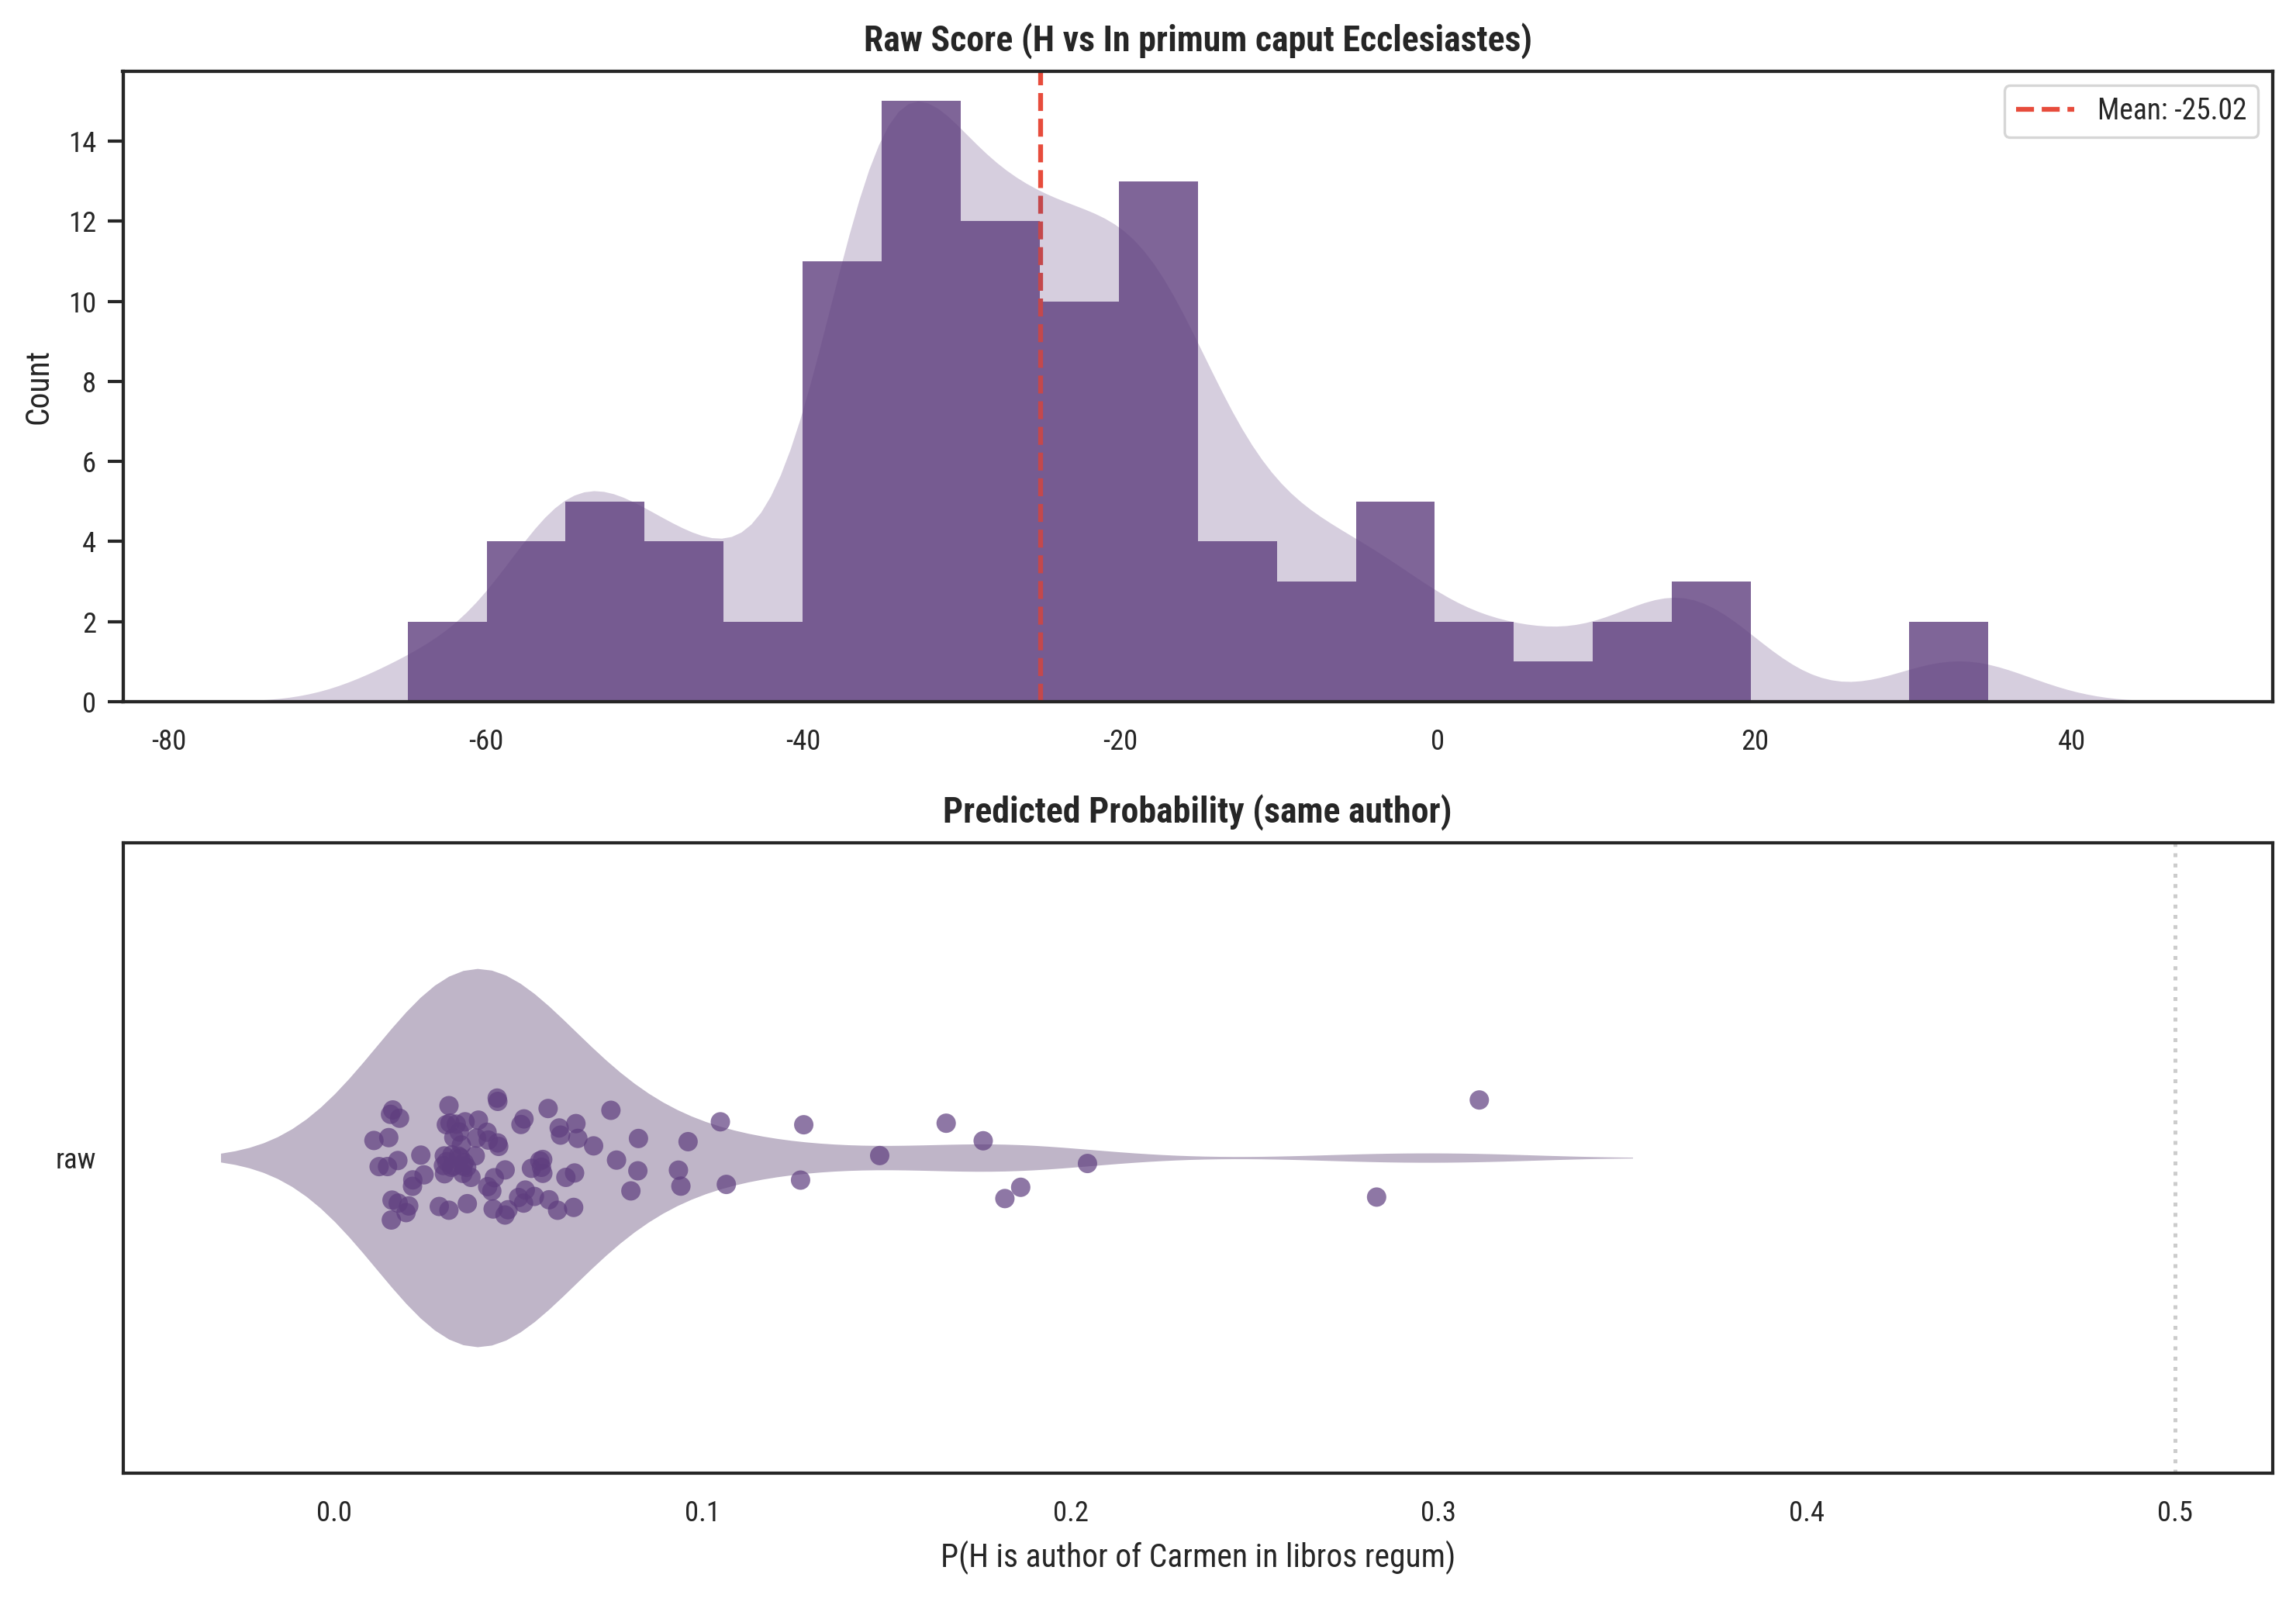

In [26]:
# Visualization: histplot of raw scores + stripplot/violin of probabilities
fig, axes = plt.subplots(2, 1, figsize=(10, 7), dpi=300)

for ax in axes:
    ax.grid(False)

color = "#5f3e7f"

# Row 1: Raw score distribution with KDE overlay
ax = axes[0]
sns.histplot(data=df, x="score", bins=20, ax=ax, color=color, alpha=0.8, linewidth=0)
ax2 = ax.twinx()
sns.kdeplot(
    data=df,
    x="score",
    ax=ax2,
    color=color,
    fill=True,
    linewidth=0,
    alpha=0.25,
    bw_adjust=0.5,
)
ax2.set_yticklabels([])
ax2.set_yticks([])
ax2.set_ylabel("")
ax.set_title("Raw Score (H vs In primum caput Ecclesiastes)", fontweight="bold", fontsize=11)
ax.set_xlabel("")
ax.set_ylabel("Count")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
mean_val = df["score"].mean()
ax.axvline(
    mean_val,
    color="#e74c3c",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {mean_val:.2f}",
)
ax.legend(loc="upper right", fontsize=9)

# Row 2: Probability stripplot + violin
ax = axes[1]
ax.grid(False)
df_plot = pd.DataFrame(
    {
        "probability": df["probability"].tolist(),
        "model": ["raw"] * len(df),
    }
)
sns.violinplot(
    data=df_plot,
    x="probability",
    y="model",
    hue="model",
    ax=ax,
    palette=[color],
    width=0.6,
    inner=None,
    density_norm="width",
    alpha=0.4,
    linewidth=0,
    legend=False,
)
sns.stripplot(
    data=df_plot,
    x="probability",
    y="model",
    hue="model",
    ax=ax,
    palette=[color],
    size=6,
    jitter=True,
    alpha=0.7,
    legend=False,
)
ax.set_title("Predicted Probability (same author)", fontweight="bold", fontsize=11)
ax.set_xlabel("P(H is author of Carmen in libros regum)")
ax.set_ylabel("")
ax.axvline(x=0.5, color="gray", linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()

## Evaluate Against All Authors

Now run the same 100 evaluations against every other author in the test corpus. For authors with fewer than 2000 tokens, we use their total token count as `known_size`.

In [28]:
# Compute known_size for each author
author_sizes = {}
for author in sorted(test_corpus.get_unique_values("author")):
    author_corpus = test_corpus.filter_by_level("author", author)
    tokens = sum(len(s.text.split()) for s in author_corpus)
    known_size = min(2000, tokens)
    author_sizes[author] = known_size
    print(f"  {author:6s}: {tokens:6d} tokens → known_size={known_size}")

  AI    :   9863 tokens → known_size=2000
  AeC   :  14745 tokens → known_size=2000
  AeP   :   5803 tokens → known_size=2000
  B     :   1991 tokens → known_size=1991
  BC    :   6995 tokens → known_size=2000
  DC    :   6446 tokens → known_size=2000
  E     :   3326 tokens → known_size=2000
  FB    :  10686 tokens → known_size=2000
  GAp   :   5978 tokens → known_size=2000
  GAr   :  11370 tokens → known_size=2000
  GB    :   5016 tokens → known_size=2000
  GC    :  12150 tokens → known_size=2000
  GM    :   3399 tokens → known_size=2000
  GP    :  14422 tokens → known_size=2000
  GVS   :   4954 tokens → known_size=2000
  GiP   :   5745 tokens → known_size=2000
  H     :   1961 tokens → known_size=1961
  HA    :   5048 tokens → known_size=2000
  HP    :   7625 tokens → known_size=2000
  IH    :   9526 tokens → known_size=2000
  II    :   8193 tokens → known_size=2000
  NLC   :   5260 tokens → known_size=2000
  OM    :   8014 tokens → known_size=2000
  OSE   :   3947 tokens → known_si

In [29]:
# Define the per-author evaluation function
@ray.remote
def run_evaluation_for_author(
    seed: int,
    known_author: str,
    known_size: int,
    target_tokens: int = 1000,
) -> dict:
    """Run a single AV evaluation: In primum caput Ecclesiastes vs a given known author."""
    rng = np.random.default_rng(seed)
    av = LambdaGAV()

    q_corpus = sample_corpus_to_token_count(ecclesiastes_corpus, target_tokens, rng)

    result = av.run_single_av_problem(
        known_entity=known_author,
        q_corpus=q_corpus,
        kr_corpus=test_corpus,
        known_tokens=known_size,
        reference_tokens=20000,
        order=8,
        num_references=10,
        rng=rng,
    )

    return {
        "author": known_author,
        "score": result["score"],
        "known_size": known_size,
    }

In [30]:
N_EVALUATIONS = 100
# Run evaluations for all authors
ray.init()
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

master_rng = np.random.default_rng(123)

all_tasks = []
task_info = []  # (author, seed) for each task

for author, known_size in author_sizes.items():
    for i in range(N_EVALUATIONS):
        seed = master_rng.integers(0, 2**32 - 1)
        all_tasks.append(
            run_evaluation_for_author.remote(seed, author, known_size, TARGET_TOKENS)
        )
        task_info.append(author)

print(f"Created {len(all_tasks)} tasks for {len(author_sizes)} authors")

# Execute all tasks
all_results = []
for _ in tqdm(range(len(all_tasks)), desc="All evaluations"):
    ready, _ = ray.wait(all_tasks, num_returns=1)
    result = ray.get(ready[0])
    all_results.append(result)
    all_tasks.remove(ready[0])

print(f"✓ Completed {len(all_results)} evaluations")
ray.shutdown()

2026-09-02 17:14:32,111	INFO worker.py:2012 -- Started a local Ray instance.


Ray initialized with 8.0 CPUs


(pid=30568) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
(pid=30568)   from pandas.core.computation.check import NUMEXPR_INSTALLED
(pid=30568) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
(pid=30568)   from pandas.core import (


Created 3800 tasks for 38 authors


All evaluations: 100%|█████████████████████| 3800/3800 [23:53<00:00,  2.65it/s]
(pid=30572) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed). [repeated 7x across cluster]
(pid=30572)   from pandas.core.computation.check import NUMEXPR_INSTALLED [repeated 7x across cluster]
(pid=30572) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed). [repeated 7x across cluster]
(pid=30572)   from pandas.core import ( [repeated 7x across cluster]


✓ Completed 3800 evaluations


In [31]:
# Convert to DataFrame and compute probabilities
df_all = pd.DataFrame(all_results)
df_all["probability"] = model.predict_proba(df_all["score"].values.reshape(-1, 1))[:, 1]

# Summary: mean probability per author
summary = df_all.groupby("author")["probability"].agg(["mean", "std", "count"]).round(4)
summary = summary.sort_values("mean", ascending=False)
print("\n=== Mean Predicted Probability by Author ===")
print(summary)


=== Mean Predicted Probability by Author ===
          mean     std  count
author                       
U3      0.8237  0.1420    100
FB      0.6343  0.2615    100
B       0.6087  0.1699    100
HA      0.5563  0.2708    100
U7      0.4693  0.2360    100
GiP     0.2486  0.1969    100
NLC     0.1356  0.1576    100
U1      0.0705  0.0486    100
H       0.0615  0.0404    100
AeC     0.0610  0.0977    100
OSE     0.0545  0.0844    100
U6      0.0539  0.0771    100
SG      0.0513  0.0359    100
GM      0.0503  0.0573    100
HP      0.0475  0.0743    100
GVS     0.0384  0.0672    100
RT      0.0224  0.0154    100
AI      0.0217  0.0354    100
U2      0.0194  0.0153    100
DC      0.0114  0.0214    100
RQ      0.0100  0.0112    100
GC      0.0072  0.0148    100
U5      0.0057  0.0281    100
U4      0.0053  0.0127    100
U9      0.0046  0.0097    100
GAr     0.0036  0.0082    100
GAp     0.0033  0.0050    100
U8      0.0032  0.0063    100
RC      0.0020  0.0021    100
BC      0.0017  0.0048  

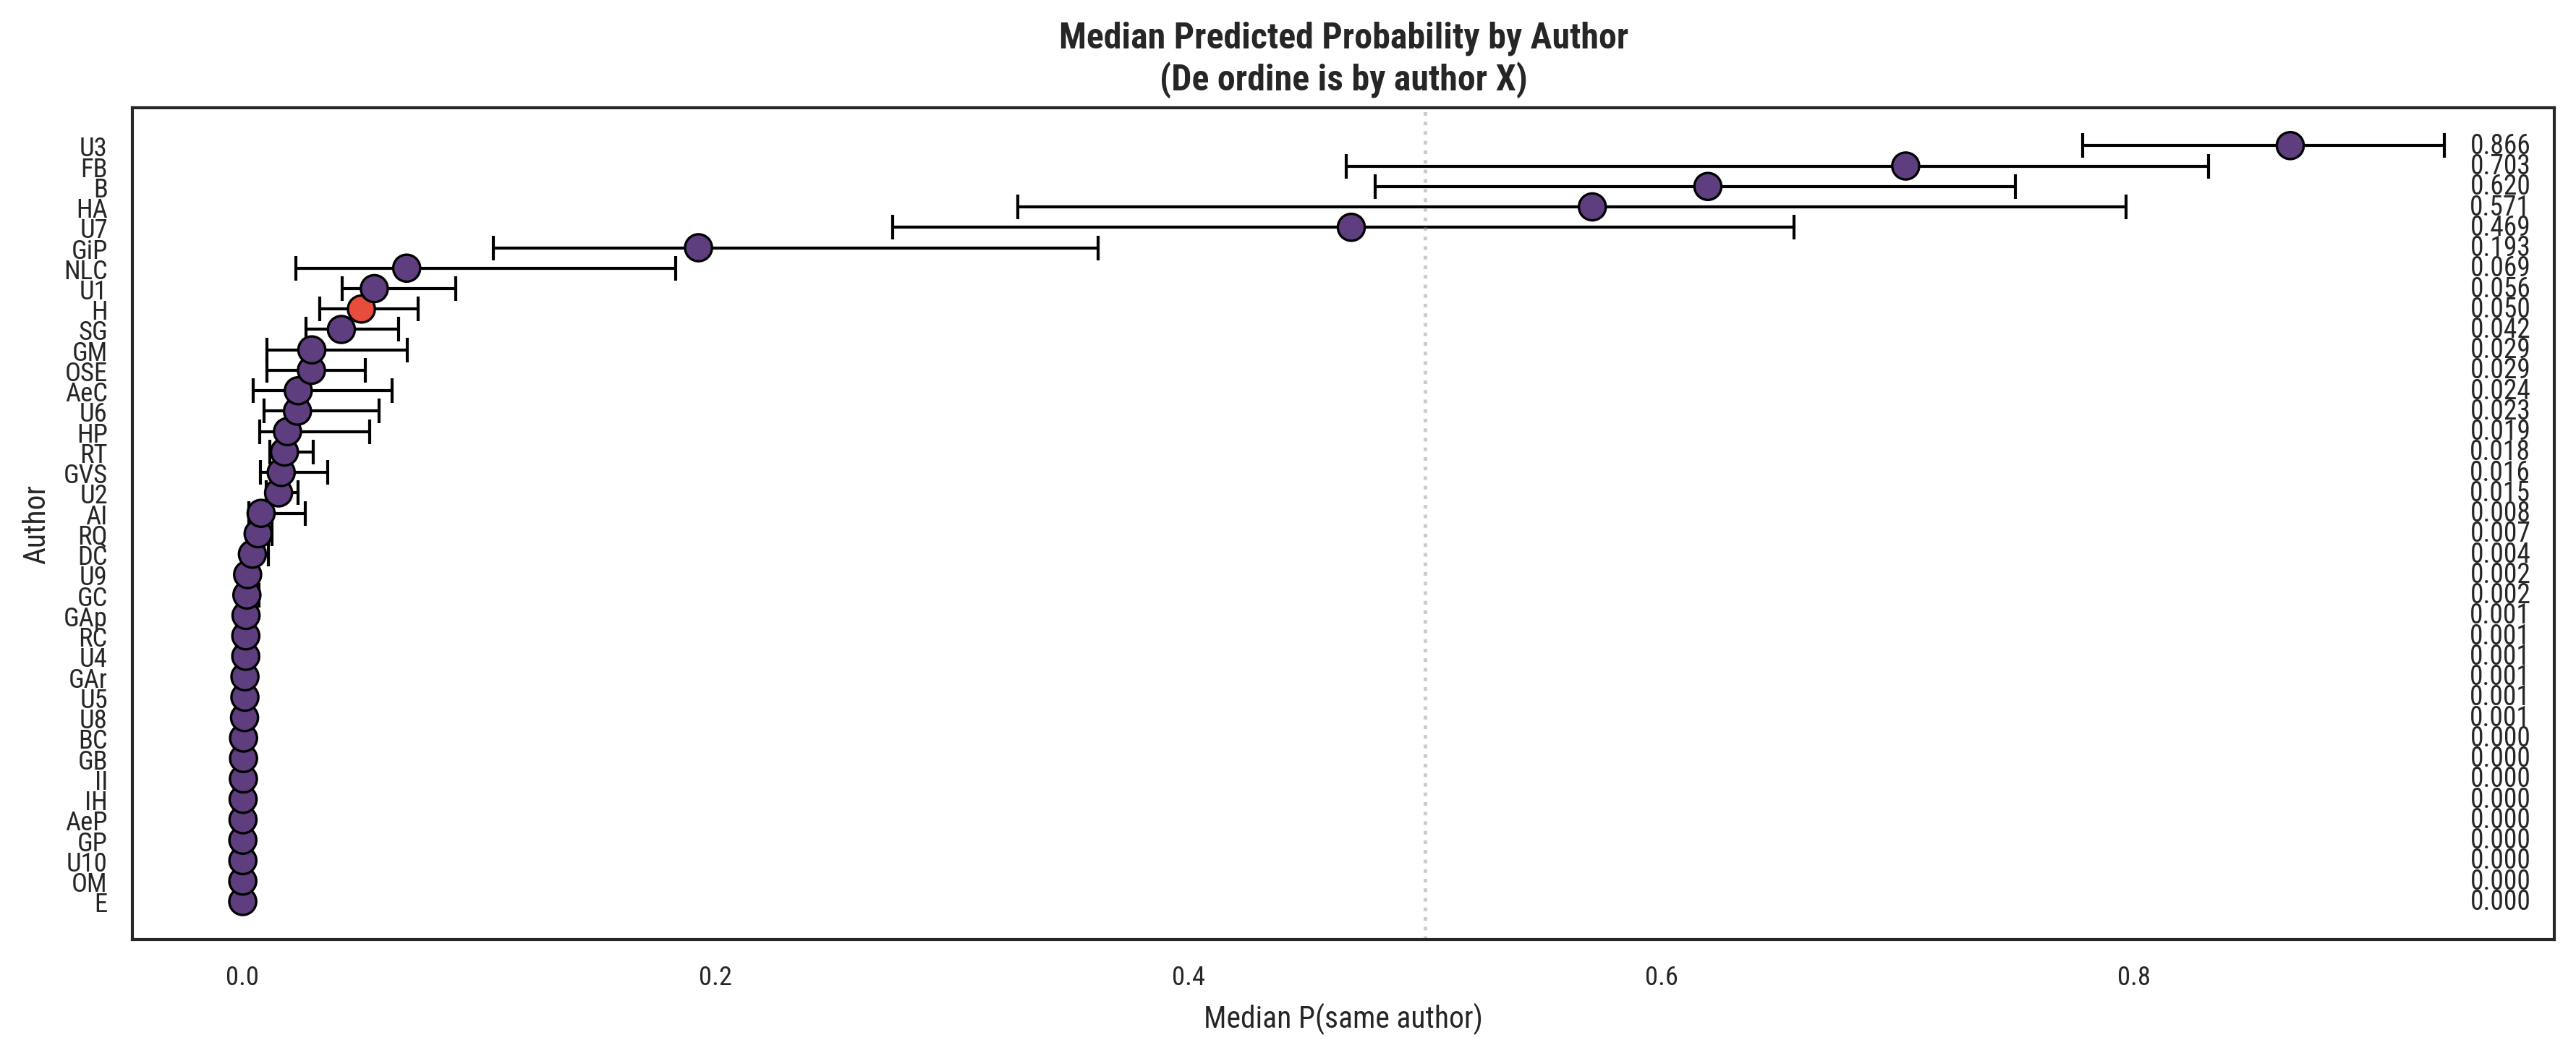

In [32]:
# Visualization: median probability per author with IQR whiskers
fig, ax = plt.subplots(figsize=(12, 5), dpi=300)
ax.grid(False)

# Compute stats per author
stats = df_all.groupby("author")["probability"].agg(
    ["median", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)]
)
stats.columns = ["median", "q25", "q75"]
stats = stats.sort_values("median", ascending=True)
authors_ordered = stats.index.tolist()

# Color: highlight H differently
colors = ["#e74c3c" if a == "H" else "#5f3e7f" for a in authors_ordered]

# IQR whiskers
for i, author in enumerate(authors_ordered):
    row = stats.loc[author]
    ax.plot(
        [row["q25"], row["q75"]],
        [i, i],
        color="black",
        linewidth=1,
        solid_capstyle="round",
    )
    for q in [row["q25"], row["q75"]]:
        ax.plot(q, i, "|", color="black", markersize=8, markeredgewidth=1)

# Median dots
ax.scatter(
    stats["median"].values,
    range(len(authors_ordered)),
    c=colors,
    s=80,
    zorder=5,
    edgecolors="black",
    linewidth=0.8,
)

ax.set_yticks(range(len(authors_ordered)))
ax.set_yticklabels(authors_ordered)
ax.set_title(
    "Median Predicted Probability by Author\n(De ordine is by author X)",
    fontweight="bold",
    fontsize=12,
)
ax.set_xlabel("Median P(same author)")
ax.set_ylabel("Author")
ax.axvline(x=0.5, color="gray", linestyle=":", alpha=0.4)

# Add value labels on the right side of the plot
xlim = ax.get_xlim()
for i, (val, author) in enumerate(zip(stats["median"].values, authors_ordered)):
    ax.text(xlim[1] - 0.01, i, f"{val:.3f}", va="center", ha="right", fontsize=9)

plt.tight_layout()
plt.show()